# Custom CNN trained from scratch on the full images (no pretrained weights)

* Input: the **whole image, only resized to 512x512** (exactly like `train.py`).
* Target: only the **class label** (first number in each `.txt` file). The bounding-box coordinates are **not used**.
* Same scene-wise train/val/test split as `train.py` (via `dataset.py` / `config.py`).

**Why a plain from-scratch CNN "learns nothing" on this data**
* All 15 images of a scene share the **same background**; only the small workpiece changes.
  The background carries no class information but fills almost all pixels.
* With ~1740 training images, a randomly initialised CNN easily memorises the training backgrounds
  (high train accuracy, chance-level val accuracy = 1/15 = 6.7%) or does not learn at all.
  A pretrained ResNet already knows what objects look like, so it does not have this problem.

**What this notebook does differently**
1. **Scene-grouped batches** (`SCENE_BATCHES = True`): every batch contains complete scenes, i.e. all 15 materials
   on the same background. Inside a batch, the background can then not tell the classes apart, so the only way to
   reduce the loss is to look at the workpiece. (Uses only the scene grouping that `dataset.py` already uses for the split.)
2. **Attention pooling**: instead of averaging the whole feature map (where the small workpiece is drowned by the
   background), the network learns by itself a weight for each image region and classifies from the weighted features.
   It is learned only from the class labels. The learned attention maps are plotted at the end (useful next to LIME).
3. A CNN design that trains well from scratch: BatchNorm after every conv, no huge fully connected layer,
   Kaiming init, AdamW with warm-up + cosine learning-rate schedule, label smoothing.
4. Augmentation without hue/saturation changes (colour is the class).

**Colab:** Runtime -> Change runtime type -> **GPU**, then run all cells top to bottom.

## 1. Setup: code + data

In [ ]:
!nvidia-smi -L

In [ ]:
# Same repo as train.ipynb (provides config.py and dataset.py)
!test -d /content/thesis || git clone https://github.com/Ahmed-AlTahan/CNN-LIME.git /content/thesis
%cd /content/thesis

In [ ]:
# Download + unzip the dataset (skipped if it is already there)
!pip -q install gdown
![ -d data/15workpieces_same_position/all_images ] || (gdown --fuzzy "https://drive.google.com/file/d/1OfQmMsNR5DDLbZUmLL2DGuHPIGFxnqy6/view?usp=drive_link" -O data.zip && mkdir -p data && unzip -q data.zip -d data)
!ls data/15workpieces_same_position/all_images/*.jpg | wc -l

## 2. Settings

In [36]:
import config

IMG_SIZE         = config.IMG_SIZE   # 512, same as train.py (whole image, only resized)
EPOCHS           = 80
LR               = 1e-3
WEIGHT_DECAY     = 0.05
PATIENCE         = 20     # early stopping on validation accuracy
SCENE_BATCHES    = True   # True: batch = complete scenes (all 15 materials, same background)
SCENES_PER_BATCH = 4      # 4 scenes x 15 images = 60 images per batch
                          # (with only 2 scenes, BatchNorm statistics depend too much on 2 backgrounds and
                          #  differ from the averaged statistics used at test time -> unstable validation)
BATCH_SIZE       = 30     # used when SCENE_BATCHES = False, and for val/test

# Training seeds: one full training run per seed. Same seed -> same result.
# For the thesis use several, e.g. [1, 2, 3, 4, 5], and report mean +- std (each run takes a while).
# NOTE: the train/val/test SPLIT always uses config.SEED, so all runs use the same scenes.
SEEDS            = [1, 2, 3]
RUN_NAME         = f"custom_cnn_full_scene{int(SCENE_BATCHES)}"

## 3. Imports

In [37]:
import copy, csv, math, os, random, time
from concurrent.futures import ThreadPoolExecutor

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # needed for deterministic matrix multiplications on GPU

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Dataset

from dataset import SimpleFischertechnikDataset

CLASS_NAMES = ["white plastic", "aluminium", "brass", "steel", "orange acryl", "yellow acryl",
               "blue acryl", "red acryl", "red plastic", "blue plastic", "yellow plastic",
               "gray plastic", "black plastic", "light wood", "dark wood"]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# Reproducibility: same seed -> same result. Use deterministic GPU algorithms
# (slightly slower; warn_only prints a warning instead of crashing if an op has no deterministic version).
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MEAN_T = torch.tensor(config.MEAN, device=device).view(1, 3, 1, 1)
STD_T = torch.tensor(config.STD, device=device).view(1, 3, 1, 1)
print(f"Using device: {device} | run: {RUN_NAME}")

Using device: cuda | run: custom_cnn_full_scene1


## 4. Dataset
Uses `SimpleFischertechnikDataset` for the split and the labels, so train/val/test are **exactly the same scenes**
as in `train.py`. Each image is loaded once, resized to 512x512 and kept in RAM as uint8 (~2 GB for all 2490 images),
so the JPEGs are not decoded again every epoch.

In [38]:
class CachedImageDataset(Dataset):
    def __init__(self, base, size):
        self.samples, self.scene_ids = base.samples, base.scene_ids
        self.scenes = [s["scene"] for s in self.samples]
        self.labels = torch.tensor([s["label"] for s in self.samples])

        def load(s):
            img = Image.open(s["img_path"]).convert("RGB").resize((size, size), Image.BILINEAR)
            return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)   # uint8, 3xHxW

        with ThreadPoolExecutor(8) as ex:
            self.images = list(ex.map(load, self.samples))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        return self.images[i], self.labels[i]


class SceneBatchSampler:
    """Each batch = all images of k randomly chosen scenes."""
    def __init__(self, scenes, k, seed):
        groups = {}
        for i, sc in enumerate(scenes):
            groups.setdefault(sc, []).append(i)
        self.groups, self.k, self.rng = list(groups.values()), k, random.Random(seed)

    def __iter__(self):
        order = self.groups[:]
        self.rng.shuffle(order)
        for b in range(0, len(order) - self.k + 1, self.k):
            yield [i for g in order[b:b + self.k] for i in g]

    def __len__(self):
        return len(self.groups) // self.k

## 5. Augmentation (on the GPU, training only)
Horizontal flip, rotation +-10 deg, shift +-10 %, zoom +-10 %, brightness/contrast +-20 %.
**No** hue/saturation changes, because colour is what separates the classes.

In [39]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - MEAN_T) / STD_T


def augment(x_uint8):
    B, dev = x_uint8.size(0), x_uint8.device
    x = x_uint8.float() / 255
    # brightness / contrast
    b = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.2
    c = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.2
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (((x - m) * c + m) * b).clamp(0, 1)
    # flip + rotation + zoom + shift in one affine warp
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(10)
    scale = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.1
    flip = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0)
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    A = torch.stack([torch.stack([cos * flip, -sin], 1),
                     torch.stack([sin * flip, cos], 1)], 1)              # B x 2 x 2
    t = (torch.rand(B, 2, device=dev) * 2 - 1) * 0.1
    grid = F.affine_grid(torch.cat([A, t.unsqueeze(2)], 2), list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    return (x - MEAN_T) / STD_T

## 6. Model
512x512 input -> 16x16 feature map (each cell covers 32x32 pixels).
A 1x1 conv gives every cell a score, softmax over the 256 cells turns the scores into attention weights,
and the class is predicted from the attention-weighted features. The attention is learned only from the class labels.

In [40]:
def conv_bn_relu(cin, cout, stride=1):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False),
                         nn.BatchNorm2d(cout), nn.ReLU(inplace=True))


class AttentionCNN(nn.Module):
    def __init__(self, num_classes=15, widths=(32, 64, 128, 256, 256), dropout=0.3):
        super().__init__()
        layers = [conv_bn_relu(3, widths[0], stride=2), conv_bn_relu(widths[0], widths[0]),
                  nn.MaxPool2d(2)]                                             # 512 -> 128
        cin = widths[0]
        for i, w in enumerate(widths[1:]):
            layers += [conv_bn_relu(cin, w), conv_bn_relu(w, w)]
            if i < len(widths) - 2:                                            # no pool after last stage
                layers.append(nn.MaxPool2d(2))
            cin = w
        self.features = nn.Sequential(*layers)                                 # 128 -> 16x16
        self.attention = nn.Conv2d(cin, 1, kernel_size=1)                      # score per cell
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(cin, num_classes))

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01); nn.init.zeros_(m.bias)
        nn.init.zeros_(self.attention.weight); nn.init.zeros_(self.attention.bias)  # start = plain average

    def forward(self, x, return_attention=False):
        f = self.features(x)                                  # B x C x h x w
        scores = self.attention(f).flatten(1).float()         # B x (h*w)
        w = scores.softmax(1).to(f.dtype)
        pooled = (f.flatten(2) * w.unsqueeze(1)).sum(2)       # attention-weighted features
        logits = self.classifier(pooled)
        return (logits, scores) if return_attention else logits


@torch.no_grad()
def run_eval(model, loader):
    """Returns loss, accuracy (%), predictions, labels."""
    model.eval()
    loss_sum, preds, labels_all = 0.0, [], []
    for images, labels in loader:
        images, labels = normalize(images.to(device)), labels.to(device)
        out = model(images)
        loss_sum += F.cross_entropy(out.float(), labels).item() * labels.size(0)
        preds.append(out.argmax(1).cpu()); labels_all.append(labels.cpu())
    preds, labels_all = torch.cat(preds).numpy(), torch.cat(labels_all).numpy()
    return loss_sum / len(labels_all), 100.0 * (preds == labels_all).mean(), preds, labels_all

## 7. Load data (a few minutes: every image is decoded once)

In [41]:
set_seed(config.SEED)
common = dict(image_dir=config.IMAGE_DIR, val_ratio=config.VAL_RATIO,
              test_ratio=config.TEST_RATIO, random_split=config.RANDOM_SPLIT, seed=config.SEED)
SimpleFischertechnikDataset.check_scene_grouping(config.IMAGE_DIR)
t0 = time.time()
train_ds, val_ds, test_ds = (CachedImageDataset(SimpleFischertechnikDataset(split=s, **common), IMG_SIZE)
                             for s in ("train", "val", "test"))
print(f"Loaded in {time.time() - t0:.0f}s")

s = [set(d.scene_ids) for d in (train_ds, val_ds, test_ds)]
assert not (s[0] & s[1] or s[0] & s[2] or s[1] & s[2]), "Scene leakage between splits!"
print(f"Scenes -> train: {len(s[0])} | val: {len(s[1])} | test: {len(s[2])}")
print(f"Images -> train: {len(train_ds)} | val: {len(val_ds)} | test: {len(test_ds)}")

def make_train_loader(seed):
    """A NEW loader with its own seeded shuffling, created at the start of every training run.
    (Re-using one loader would continue its random state, so re-running training gave different results.)"""
    if SCENE_BATCHES:
        return DataLoader(train_ds, batch_sampler=SceneBatchSampler(train_ds.scenes, SCENES_PER_BATCH, seed))
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=g)

val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

Scene check: 166 blocks, 0 suspicious.
Loaded in 28s
Scenes -> train: 116 | val: 25 | test: 25
Images -> train: 1740 | val: 375 | test: 375


## 8. Check the inputs (augmented training images as the network sees them)

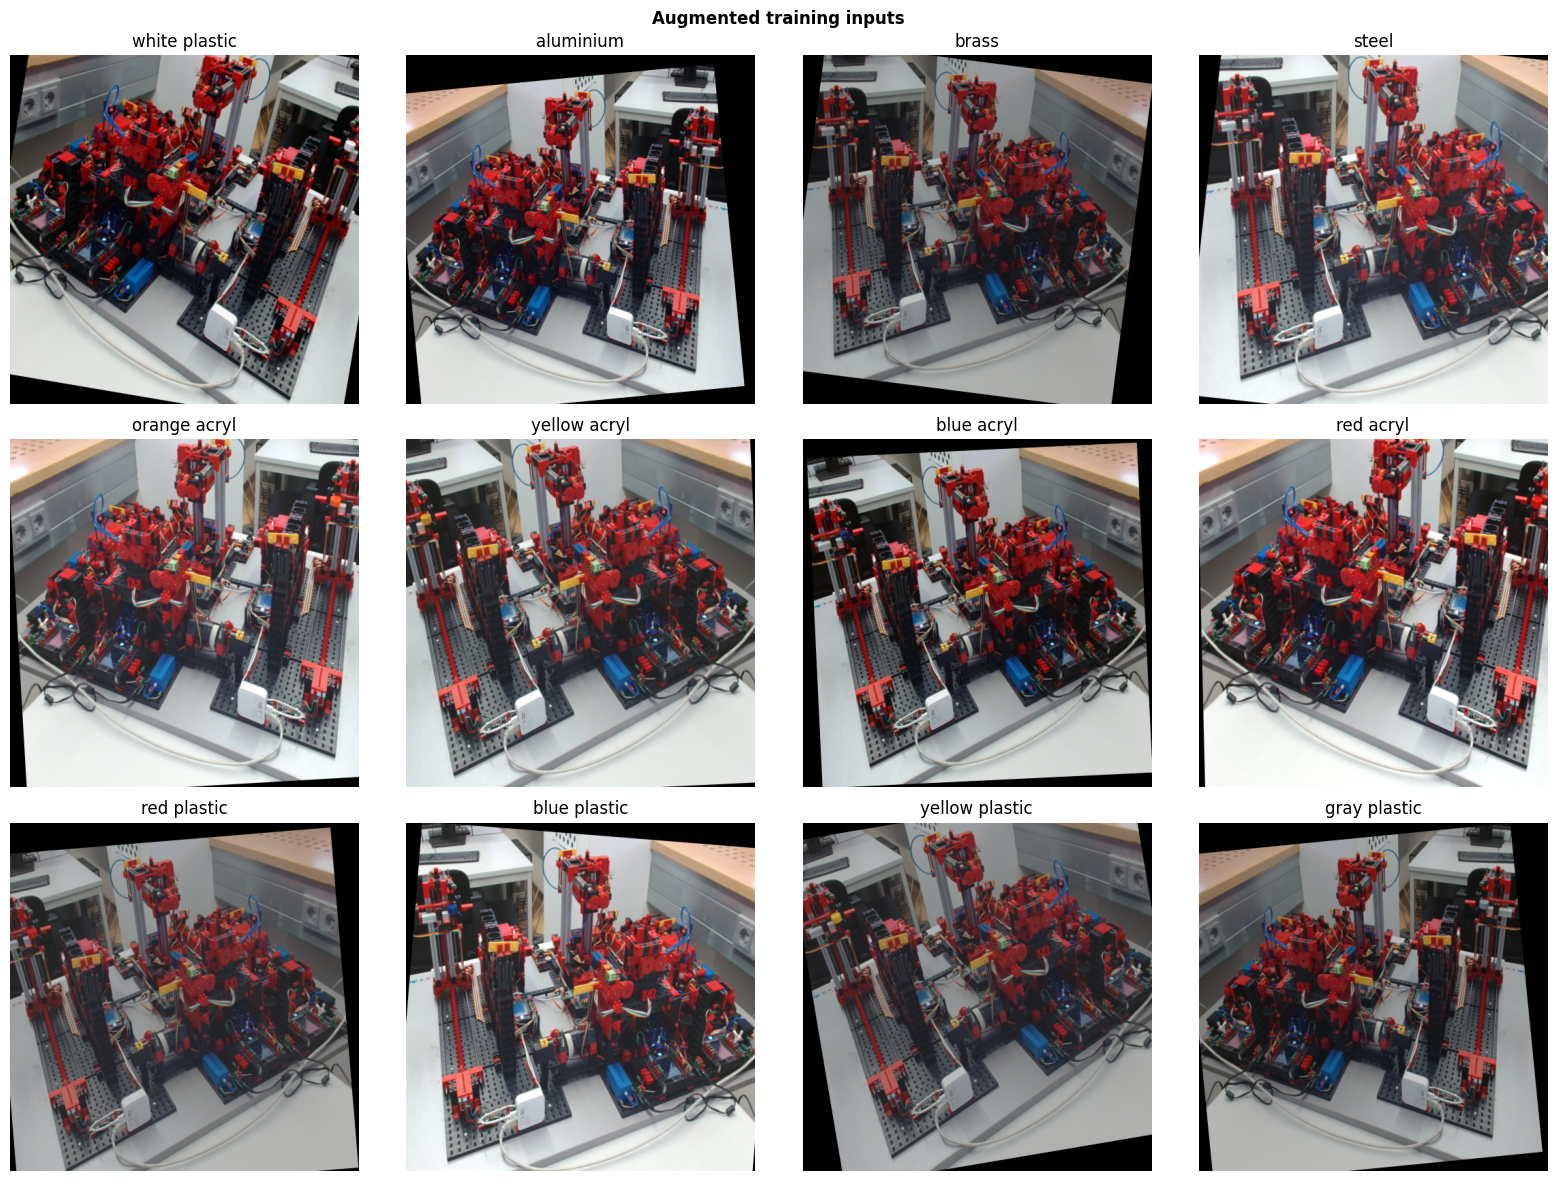

In [42]:
set_seed(0)
images, labels = next(iter(make_train_loader(0)))
x = augment(images[:12].to(device)).cpu()
mean, std = np.array(config.MEAN), np.array(config.STD)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, img, lbl in zip(axes.flatten(), x, labels[:12]):
    ax.imshow(np.clip(std * img.permute(1, 2, 0).numpy() + mean, 0, 1))
    ax.set_title(CLASS_NAMES[int(lbl)]); ax.axis("off")
plt.suptitle("Augmented training inputs", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{RUN_NAME}_inputs.png", dpi=100); plt.show()

## 9. Sanity check: overfit ONE batch
A fresh model must reach ~100% on a single fixed batch. If it does not, something in the pipeline is broken.
If it does, the pipeline can learn and any remaining problem is generalisation.
(Uses a separate model, so it does not affect the real training.)

In [43]:
set_seed(0)
sanity_model = AttentionCNN(config.NUM_CLASSES).to(device)
images, labels = next(iter(make_train_loader(0)))
images, labels = normalize(images.to(device)), labels.to(device)
opt = torch.optim.Adam(sanity_model.parameters(), lr=1e-3)
sanity_model.train()
for step in range(1, 151):
    opt.zero_grad()
    out = sanity_model(images)
    loss = F.cross_entropy(out, labels)
    loss.backward(); opt.step()
    if step == 1 or step % 25 == 0:
        acc = 100.0 * (out.argmax(1) == labels).float().mean().item()
        print(f"step {step:4d} | loss {loss.item():.4f} | batch acc {acc:.1f}%")
del sanity_model, opt
torch.cuda.empty_cache()

step    1 | loss 2.7084 | batch acc 5.0%
step   25 | loss 1.3959 | batch acc 50.0%
step   50 | loss 0.0624 | batch acc 100.0%
step   75 | loss 0.0018 | batch acc 100.0%
step  100 | loss 0.0004 | batch acc 100.0%
step  125 | loss 0.0001 | batch acc 100.0%
step  150 | loss 0.0001 | batch acc 100.0%


## 10. Training (one full run per seed in `SEEDS`)
Every run starts from scratch: new model, new seeded data order, new optimizer.
Running this cell again gives the same results for the same seeds.

In [44]:
def train_one_run(seed):
    set_seed(seed)
    train_loader = make_train_loader(seed)
    model = AttentionCNN(config.NUM_CLASSES).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    steps_per_epoch = len(train_loader)
    total_steps, warmup = EPOCHS * steps_per_epoch, 3 * steps_per_epoch

    def lr_factor(step):   # 3 epochs linear warm-up, then cosine decay to 0
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)

    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    init_loss, init_acc, _, _ = run_eval(model, val_loader)
    print(f"Before training: val loss {init_loss:.3f} (expected ~{math.log(config.NUM_CLASSES):.3f}) "
          f"| val acc {init_acc:.1f}%")

    history = []
    best_val_acc, best_val_loss, best_weights, best_epoch, bad_epochs = -1.0, 1e9, None, 0, 0
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = augment(images.to(device)), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(images)
                loss = F.cross_entropy(out.float(), labels, label_smoothing=0.1)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update(); scheduler.step()
            loss_sum += loss.item() * labels.size(0)
            total += labels.size(0)
            correct += (out.argmax(1) == labels).sum().item()

        val_loss, val_acc, _, _ = run_eval(model, val_loader)
        tr_loss, tr_acc = loss_sum / total, 100.0 * correct / total
        history.append((epoch, tr_loss, tr_acc, val_loss, val_acc))
        print(f"[seed {seed}] Epoch [{epoch:3d}/{EPOCHS}] | Train Loss {tr_loss:.4f} | Train Acc {tr_acc:6.2f}% "
              f"| Val Loss {val_loss:.4f} | Val Acc {val_acc:6.2f}% "
              f"| lr {scheduler.get_last_lr()[0]:.2e} | {time.time() - t0:.0f}s")

        if val_acc > best_val_acc or (val_acc == best_val_acc and val_loss < best_val_loss):
            best_val_acc, best_val_loss, best_epoch, bad_epochs = val_acc, val_loss, epoch, 0
            best_weights = copy.deepcopy(model.state_dict())
            print("   ---> New best validation accuracy, weights kept.")
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f"\nEarly stopping: no validation improvement for {PATIENCE} epochs.")
                break

    model.load_state_dict(best_weights)
    path = f"{RUN_NAME}_seed{seed}.pth"
    torch.save(model.state_dict(), path)
    print(f"[seed {seed}] Best validation accuracy: {best_val_acc:.2f}% (epoch {best_epoch}) -> saved {path}")
    return dict(seed=seed, model=model, history=history, best_val_acc=best_val_acc, best_epoch=best_epoch)


print(f"AttentionCNN from scratch: "
      f"{sum(p.numel() for p in AttentionCNN(config.NUM_CLASSES).parameters()) / 1e6:.2f} M parameters")
runs = []
for seed in SEEDS:
    print(f"\n==================== Training run with seed {seed} ====================")
    runs.append(train_one_run(seed))

AttentionCNN from scratch: 2.36 M parameters

==================== Training run with seed 1 ====================
Before training: val loss 2.708 (expected ~2.708) | val acc 6.7%
[seed 1] Epoch [  1/80] | Train Loss 2.7103 | Train Acc   6.72% | Val Loss 2.7092 | Val Acc   6.13% | lr 3.45e-04 | 11s
   ---> New best validation accuracy, weights kept.
[seed 1] Epoch [  2/80] | Train Loss 2.7053 | Train Acc   7.41% | Val Loss 2.7144 | Val Acc   6.40% | lr 6.78e-04 | 11s
   ---> New best validation accuracy, weights kept.
[seed 1] Epoch [  3/80] | Train Loss 2.6999 | Train Acc   8.51% | Val Loss 4.7161 | Val Acc   6.67% | lr 1.00e-03 | 11s
   ---> New best validation accuracy, weights kept.
[seed 1] Epoch [  4/80] | Train Loss 2.7127 | Train Acc   5.40% | Val Loss 2.7112 | Val Acc   6.93% | lr 1.00e-03 | 11s
   ---> New best validation accuracy, weights kept.
[seed 1] Epoch [  5/80] | Train Loss 2.7105 | Train Acc   5.80% | Val Loss 2.7082 | Val Acc   5.60% | lr 9.98e-04 | 11s
[seed 1] Epoch

## 11. Training curves (all seeds)

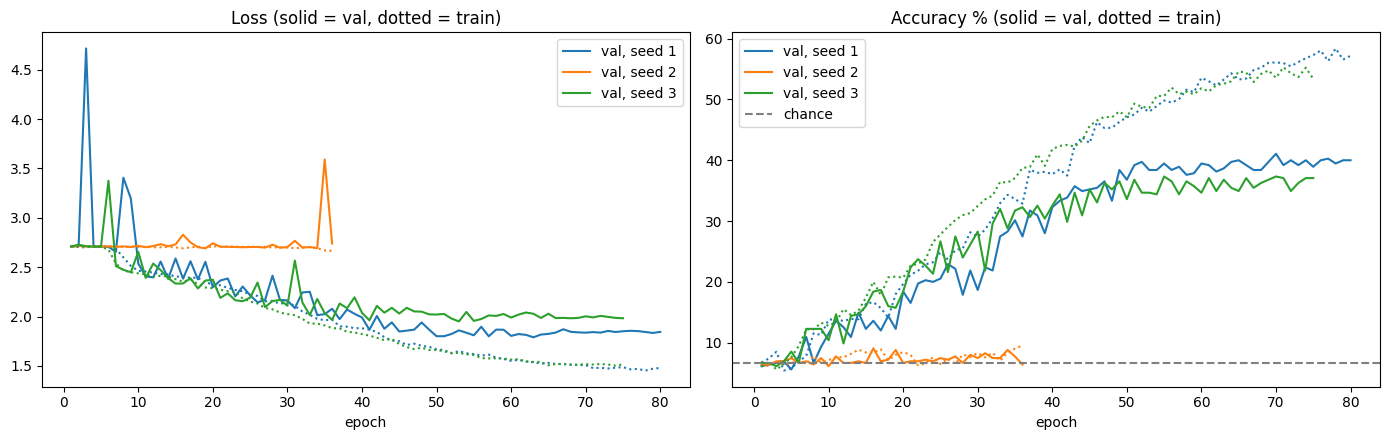

In [45]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
for r in runs:
    h = np.array(r["history"])
    line, = a1.plot(h[:, 0], h[:, 3], label=f"val, seed {r['seed']}")
    a1.plot(h[:, 0], h[:, 1], ":", color=line.get_color())
    a2.plot(h[:, 0], h[:, 4], color=line.get_color(), label=f"val, seed {r['seed']}")
    a2.plot(h[:, 0], h[:, 2], ":", color=line.get_color())
a2.axhline(100 / config.NUM_CLASSES, ls="--", c="gray", label="chance")
a1.set_title("Loss (solid = val, dotted = train)"); a1.set_xlabel("epoch"); a1.legend()
a2.set_title("Accuracy % (solid = val, dotted = train)"); a2.set_xlabel("epoch"); a2.legend()
plt.tight_layout(); plt.savefig(f"{RUN_NAME}_curves.png", dpi=150); plt.show()

## 12. Test set
Every run is evaluated on the test set once, with its best-on-validation weights.
Report **mean +- std over the seeds**. The detailed analysis below is done for the run with the best
**validation** accuracy (never pick a run by its test accuracy).

seed | best val acc | test acc
   1 |       41.07% |   44.53%
   2 |        9.07% |    9.87%
   3 |       37.33% |   41.07%
TEST accuracy over 3 seeds: 31.82% +- 15.59% (min 9.87%, max 44.53%)

Detailed analysis for seed 1 (best validation accuracy 41.07%):

                precision    recall  f1-score   support

 white plastic     0.1569    0.3200    0.2105        25
     aluminium     0.0000    0.0000    0.0000        25
         brass     0.7391    0.6800    0.7083        25
         steel     0.0000    0.0000    0.0000        25
  orange acryl     0.8462    0.8800    0.8627        25
  yellow acryl     0.7857    0.8800    0.8302        25
    blue acryl     0.1600    0.1600    0.1600        25
     red acryl     0.6400    0.6400    0.6400        25
   red plastic     0.4211    0.3200    0.3636        25
  blue plastic     0.1818    0.0800    0.1111        25
yellow plastic     0.9524    0.8000    0.8696        25
  gray plastic     0.1296    0.2800    0.1772        25
 black plast

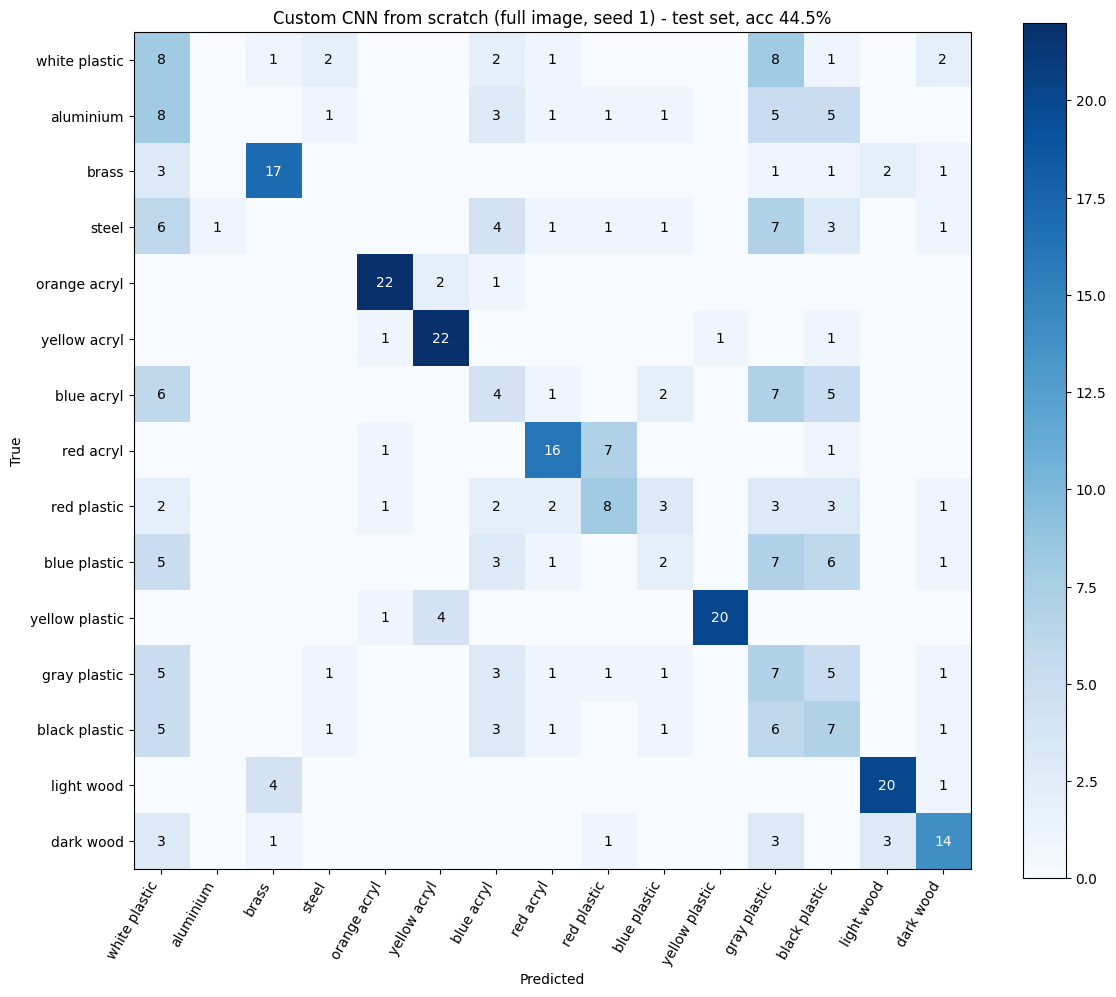

In [46]:
print("seed | best val acc | test acc")
for r in runs:
    _, r["test_acc"], r["preds"], r["labels"] = run_eval(r["model"], test_loader)
    print(f"{r['seed']:4d} | {r['best_val_acc']:11.2f}% | {r['test_acc']:7.2f}%")
test_accs = np.array([r["test_acc"] for r in runs])
print("========================================")
print(f"TEST accuracy over {len(runs)} seeds: {test_accs.mean():.2f}% +- {test_accs.std():.2f}% "
      f"(min {test_accs.min():.2f}%, max {test_accs.max():.2f}%)")
print("========================================\n")

best_run = max(runs, key=lambda r: r["best_val_acc"])
model, preds, labels_all, test_acc = best_run["model"], best_run["preds"], best_run["labels"], best_run["test_acc"]
print(f"Detailed analysis for seed {best_run['seed']} (best validation accuracy {best_run['best_val_acc']:.2f}%):\n")
print(classification_report(labels_all, preds, labels=list(range(config.NUM_CLASSES)),
                            target_names=CLASS_NAMES, digits=4, zero_division=0))

scenes = np.array(test_ds.scenes)
scene_acc = {sc: (preds[scenes == sc] == labels_all[scenes == sc]).mean() for sc in np.unique(scenes)}
v = np.array(list(scene_acc.values()))
print(f"Per-scene accuracy: mean {v.mean()*100:.1f}% | std {v.std()*100:.1f}% | min {v.min()*100:.1f}% | max {v.max()*100:.1f}%")
print("Worst scenes:", ", ".join(f"{sc}: {a*100:.0f}%" for sc, a in sorted(scene_acc.items(), key=lambda kv: kv[1])[:5]))

with open(f"predictions_{RUN_NAME}_test.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["img_path", "scene", "true", "pred"])
    for smp, p in zip(test_ds.samples, preds):
        w.writerow([smp["img_path"], smp["scene"], smp["label"], int(p)])

cm = confusion_matrix(labels_all, preds, labels=list(range(config.NUM_CLASSES)))
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j]:
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(config.NUM_CLASSES), CLASS_NAMES, rotation=60, ha="right")
plt.yticks(range(config.NUM_CLASSES), CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Custom CNN from scratch (full image, seed {best_run['seed']}) - test set, acc {test_acc:.1f}%")
plt.tight_layout(); plt.savefig(f"{RUN_NAME}_confusion_test.png", dpi=200); plt.show()

## 13. Where does the model look? (learned attention on test images)
The attention was learned from the class labels only. If it lights up on the workpiece, the model has found the
relevant region by itself; if it lights up on the background, it relies on shortcuts.

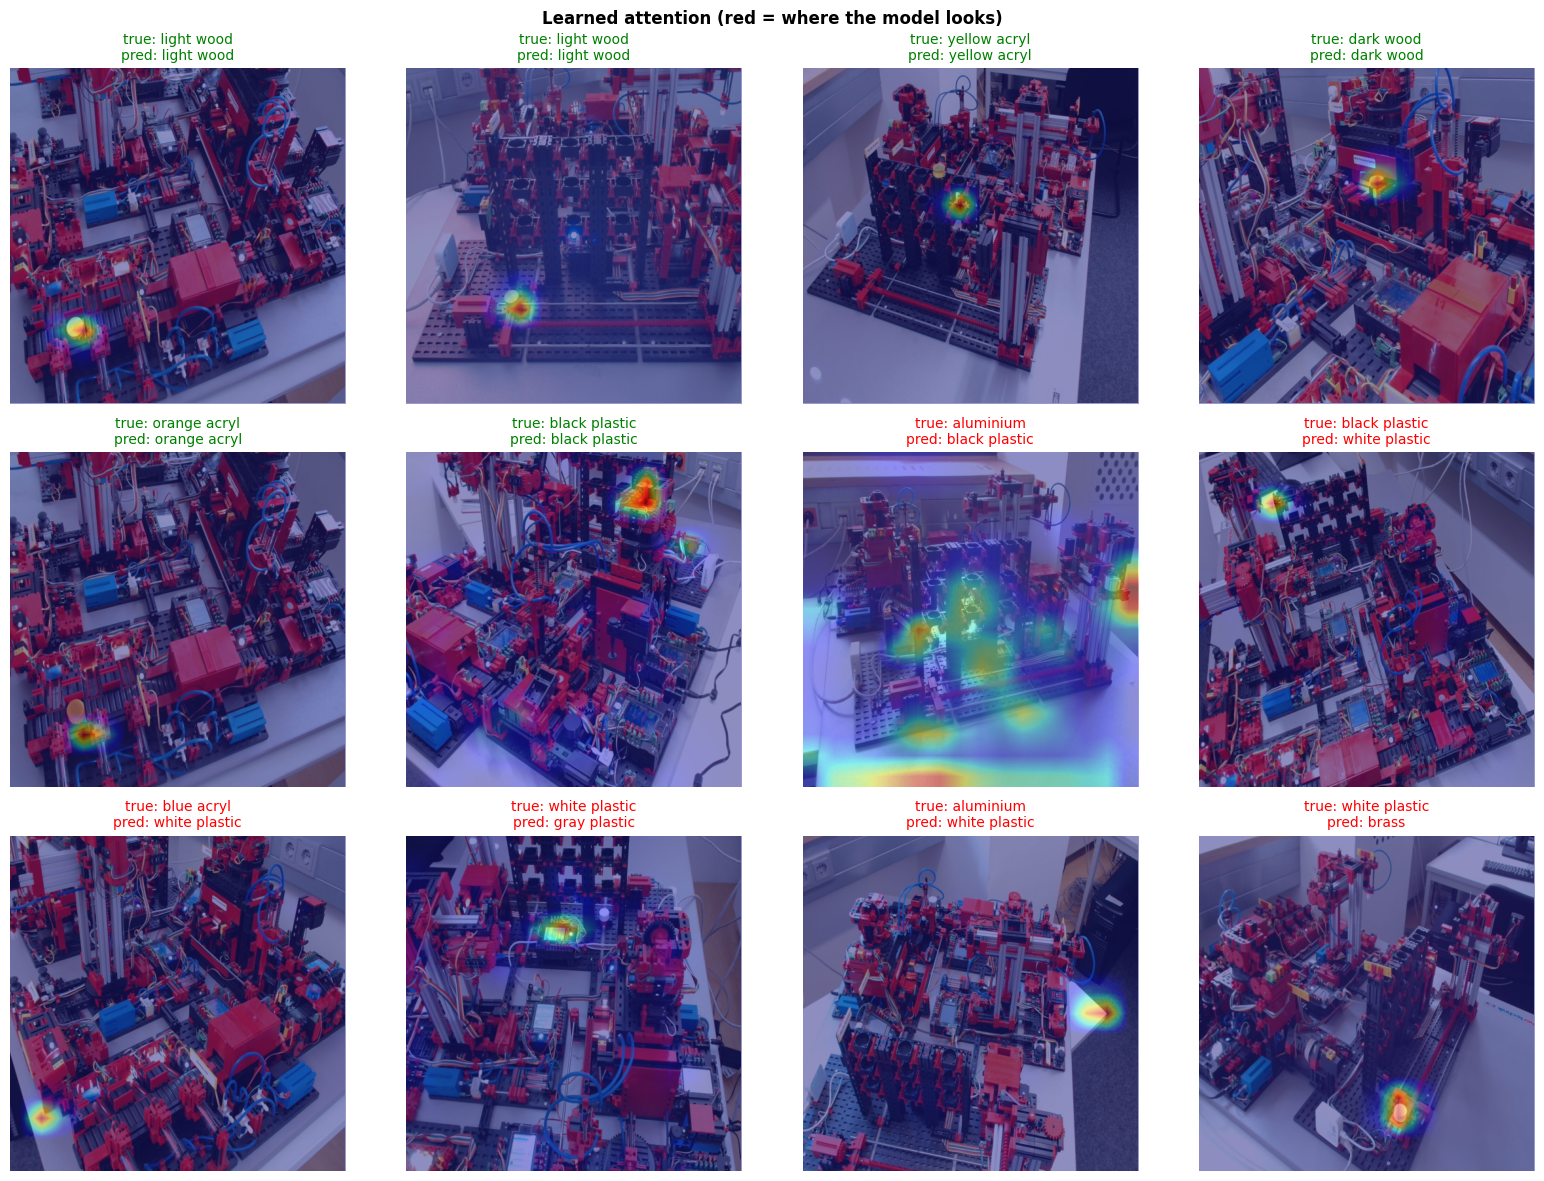

In [47]:
@torch.no_grad()
def attention_maps(idxs):
    model.eval()
    x = normalize(torch.stack([test_ds.images[i] for i in idxs]).to(device))
    _, scores = model(x, return_attention=True)
    g = int(math.isqrt(scores.size(1)))
    return scores.softmax(1).view(-1, g, g).cpu().numpy()

rng = random.Random(1)
wrong = [i for i in range(len(preds)) if preds[i] != labels_all[i]]
right = [i for i in range(len(preds)) if preds[i] == labels_all[i]]
idxs = rng.sample(right, min(6, len(right))) + rng.sample(wrong, min(6, len(wrong)))
maps = attention_maps(idxs)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax in axes.flatten():
    ax.axis("off")
for ax, i, heat in zip(axes.flatten(), idxs, maps):
    ax.imshow(test_ds.images[i].permute(1, 2, 0).numpy())
    ax.imshow(heat, cmap="jet", alpha=0.4, extent=(0, IMG_SIZE, IMG_SIZE, 0), interpolation="bilinear")
    ok = preds[i] == labels_all[i]
    ax.set_title(f"true: {CLASS_NAMES[labels_all[i]]}\npred: {CLASS_NAMES[preds[i]]}",
                 color="green" if ok else "red", fontsize=10)
plt.suptitle("Learned attention (red = where the model looks)", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{RUN_NAME}_attention_test.png", dpi=100); plt.show()

## 14. Save results to Google Drive

In [48]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p "/content/drive/MyDrive/thesis_results"
!cp {RUN_NAME}* predictions_{RUN_NAME}_test.csv "/content/drive/MyDrive/thesis_results/"
!ls -lh "/content/drive/MyDrive/thesis_results/"

Mounted at /content/drive
total 114M
-rw------- 1 root root 242K Nov  8 13:45 confusion_matrix_15x15_test.png
-rw------- 1 root root 2.4M Nov 11 21:26 custom_cnn_full_scene1_attention_test.png
-rw------- 1 root root 237K Nov 11 21:26 custom_cnn_full_scene1_confusion_test.png
-rw------- 1 root root 179K Nov 11 21:26 custom_cnn_full_scene1_curves.png
-rw------- 1 root root 2.5M Nov 11 21:26 custom_cnn_full_scene1_inputs.png
-rw------- 1 root root 9.1M Nov 11 21:26 custom_cnn_full_scene1.pth
-rw------- 1 root root 9.1M Nov 11 21:26 custom_cnn_full_scene1_seed1.pth
-rw------- 1 root root 9.1M Nov 11 21:26 custom_cnn_full_scene1_seed2.pth
-rw------- 1 root root 9.1M Nov 11 21:26 custom_cnn_full_scene1_seed3.pth
-rw------- 1 root root  43M Nov  8 13:39 fischertechnik_cnn.pth
-rw------- 1 root root  28K Nov 11 21:26 predictions_custom_cnn_full_scene1_test.csv
-rw------- 1 root root  28K Nov  8 13:45 predictions_test.csv
-rw------- 1 root root  14M Nov  8 13:45 sample_predictions_grid_test.png